In [106]:
import math
import copy
import os
import re
import json
import random
from collections import defaultdict
import xml.etree.ElementTree as ET
from collections import defaultdict

from shapely.geometry import Polygon as ShapelyPolygon, MultiPolygon, box
from shapely.affinity import translate, rotate
from shapely.ops import unary_union
from shapely.geometry import box


import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.collections import PatchCollection

from svgpathtools import svg2paths2

import numpy as np

In [21]:
def extract_color(attr):
    """
    Extract fill or stroke color from SVG attributes.
    Supports hex and rgb() styles from CorelDRAW.
    """

    # Direct attributes
    if attr.get("fill") and attr["fill"] != "none":
        return attr["fill"]

    if attr.get("stroke") and attr["stroke"] != "none":
        return attr["stroke"]

    style = attr.get("style", "")

    # Hex colors
    m = re.search(r"fill:\s*(#[0-9A-Fa-f]{6})", style)
    if m:
        return m.group(1)

    m = re.search(r"stroke:\s*(#[0-9A-Fa-f]{6})", style)
    if m:
        return m.group(1)

    # rgb() colors (Corel)
    m = re.search(r"(fill|stroke):\s*rgb\([^)]+\)", style)
    if m:
        return m.group(0)  # use full rgb(...) string as key

    return None

def parse_filename(filename):
    """
    JB_FRONT_16-18-20.svg  → sizes = ['16','18','20']
    JB_FRONT_M-L-XL.svg    → sizes = ['M','L','XL']
    """

    name = os.path.splitext(filename)[0]

    parts = name.split("_")
    if len(parts) < 3:
        raise ValueError(f"Invalid filename format: {filename}")

    brand = parts[0]
    part = parts[1].upper()
    size_list = parts[2]

    sizes = size_list.split("-")

    return part, sizes

def svg_path_to_polygon(path, svg_attr, samples=40):
    # --- Parse viewBox ---
    vb_x, vb_y, vb_w, vb_h = map(float, svg_attr["viewBox"].split())

    # --- Parse physical size in mm ---
    width_mm = float(svg_attr["width"].replace("mm", ""))
    height_mm = float(svg_attr["height"].replace("mm", ""))

    scale_x = width_mm / vb_w
    scale_y = height_mm / vb_h

    raw = []
    for seg in path:
        for t in np.linspace(0, 1, samples):
            pt = seg.point(t)
            raw.append((pt.real, pt.imag))

    # Convert to inches
    pts = []
    for x, y in raw:
        x_mm = (x - vb_x) * scale_x
        y_mm = (y - vb_y) * scale_y
        pts.append((x_mm / 25.4, y_mm / 25.4))

    # Flip Y and normalize
    max_y = max(y for _, y in pts)
    pts = [(x, max_y - y) for x, y in pts]

    min_x = min(x for x, _ in pts)
    min_y = min(y for _, y in pts)
    pts = [(x - min_x, y - min_y) for x, y in pts]

    return pts

def load_svg_file(svg_path):
    paths, attrs, svg_attr = svg2paths2(svg_path)

    colored_groups = defaultdict(list)
    uncolored_paths = []

    for path, attr in zip(paths, attrs):
        color = extract_color(attr)
        if color is None:
            uncolored_paths.append(path)
        else:
            colored_groups[color].append(path)

    polygons = []

    # --- Case 1: color-based grouping ---
    if colored_groups:
        for color, group in colored_groups.items():
            pts = []
            for p in group:
                pts.extend(svg_path_to_polygon(p, svg_attr))

            poly = ShapelyPolygon(pts)

            if poly.area > 1e-3:
                polygons.append(poly)

    # --- Case 2: fallback (no colors) ---
    else:
        for p in paths:
            pts = svg_path_to_polygon(p, svg_attr)
            poly = ShapelyPolygon(pts)

            if poly.area > 1e-3:
                polygons.append(poly)
    
    if not polygons:
        raise ValueError(f"No valid polygons found in {svg_path}")

    return polygons

def assign_sizes(polygons, sizes):
    assert len(polygons) == len(sizes), (
        f"Size count mismatch: {len(polygons)} polygons vs {len(sizes)} sizes"
    )

    areas = [(poly.area, poly) for poly in polygons]
    areas.sort(key=lambda x: x[0])  # smallest → largest
    validate_monotonic_areas(polygons)
    result = []
    for size, (_, poly) in zip(sizes, areas):
        result.append((size, list(poly.exterior.coords)))

    return result

def validate_monotonic_areas(polygons):
    areas = sorted(poly.area for poly in polygons)
    for i in range(len(areas) - 1):
        ratio = areas[i + 1] / areas[i]
        if ratio < 1.02:
            raise ValueError(
                "Two sizes have nearly identical area. "
                "Check colors or duplicate patterns."
            )
def process_design_folder(folder_path):
    all_shapes = []

    for file in os.listdir(folder_path):
        if not file.lower().endswith(".svg"):
            continue

        part, sizes = parse_filename(file)
        svg_path = os.path.join(folder_path, file)

        polygons = load_svg_file(svg_path)
        sized_polys = assign_sizes(polygons, sizes)

        for size, poly in sized_polys:
            all_shapes.append({
                "part": part,
                "size": size,
                "polygon": poly
            })

    # Save structured output
    out_path = os.path.join(folder_path, "parsed_shapes.json")
    with open(out_path, "w") as f:
        json.dump(all_shapes, f, indent=2)

    return all_shapes

def evaluate_kpis(placed_shapes, strip_width):
    max_y = 0.0
    used_area = 0.0

    for item in placed_shapes:
        poly = item["polygon"]

        for _, y in poly:
            max_y = max(max_y, y)

        area = 0.0
        n = len(poly)
        for i in range(n):
            x1, y1 = poly[i]
            x2, y2 = poly[(i + 1) % n]
            area += (x1 * y2 - x2 * y1)
        used_area += abs(area) / 2.0

    total_area = strip_width * max_y
    empty_ratio = 1.0 - (used_area / total_area) if total_area > 0 else 0.0

    return {
        "layer_length_in": max_y,
        "used_area_in2": used_area,
        "total_area_in2": total_area,
        "empty_ratio": empty_ratio
    }
def rotate_180(polygon):
    """
    Rotate polygon 180° around origin and normalize to (0,0).
    """
    rotated = [(-x, -y) for x, y in polygon]

    min_x = min(x for x, _ in rotated)
    min_y = min(y for _, y in rotated)

    normalized = [(x - min_x, y - min_y) for x, y in rotated]
    return normalized

def poly_width_height(poly):
    minx, miny, maxx, maxy = poly.bounds
    return maxx - minx, maxy - miny


In [89]:
def clean_polygon(poly):
    if not poly.is_valid:
        poly = poly.buffer(0)
    return poly
    
def occupied_union(placed_polys):
    if not placed_polys:
        return None

    try:
        u = unary_union(placed_polys)
        if not u.is_valid:
            u = u.buffer(0)
        return u

    except Exception:
        # last-resort repair
        repaired = [p.buffer(0) for p in placed_polys]
        return unary_union(repaired)


def strip_envelope(strip_width, height):
    return ShapelyPolygon([
        (0, 0),
        (strip_width, 0),
        (strip_width, height),
        (0, height)
    ])


def compute_free_space(placed_polys, strip_width):
    if not placed_polys:
        return strip_envelope(strip_width, 1000)

    cleaned = [clean_polygon(p) for p in placed_polys]

    max_y = max(p.bounds[3] for p in cleaned) + 5
    strip = strip_envelope(strip_width, max_y)

    occupied = unary_union(cleaned)

    if not occupied.is_valid:
        occupied = occupied.buffer(0)

    free = strip.difference(occupied)

    if not free.is_valid:
        free = free.buffer(0)

    return free



def extract_cavities(free_space, min_area=5.0):
    if free_space.is_empty:
        return []

    if free_space.geom_type == "Polygon":
        regions = [free_space]
    else:
        regions = list(free_space.geoms)

    cleaned = []
    for r in regions:
        if r.area >= min_area and r.is_valid:
            cleaned.append(r)

    return cleaned


def cavity_anchor_points(cavity):
    minx, miny, maxx, maxy = cavity.bounds

    return [
        (minx, miny),
        (minx, maxy),
        (maxx, miny),
        (maxx, maxy),
        cavity.centroid.coords[0]
    ]
    
def free_space_candidates(free_space):
    candidates = []

    if isinstance(free_space, ShapelyPolygon):
        candidates.extend(list(free_space.exterior.coords))

    elif isinstance(free_space, MultiPolygon):
        for poly in free_space.geoms:
            candidates.extend(list(poly.exterior.coords))

    # Keep only valid bottom-left candidates
    return [(x, y) for x, y in candidates if x >= 0 and y >= 0]


def fits_in_free_space(poly, x, y, free_space):
    minx, miny, _, _ = poly.bounds
    placed = translate(poly, xoff=x - minx, yoff=y - miny)
    return free_space.contains(placed)


In [83]:
def candidate_positions(
    skyline,
    placed_polys,
    strip_width,
    piece_width,
    piece_height
):
    candidates = []

    # 1️⃣ Skyline-based candidates
    for xs, xe, h in skyline:
        if xs + piece_width <= strip_width:
            candidates.append((xs, h))

    # 2️⃣ Cavity-based candidates
    if placed_polys:
        occupied = occupied_union(placed_polys)
        strip = strip_envelope(strip_width, max(p.bounds[3] for p in placed_polys))
        free_space = compute_free_space(strip, occupied)
        cavities = extract_cavities(free_space)

        for cav in cavities:
            for x, y in cavity_anchor_points(cav):
                if x + piece_width <= strip_width:
                    candidates.append((x, y))

    return candidates


In [62]:
SIZE_ORDER = {
    "XS": 0,
    "S": 1,
    "M": 2,
    "L": 3,
    "XL": 4,
    "XXL": 5,
    "XXXL": 6
}

def size_rank(shape):
    """
    Converts size to a sortable numeric rank.
    Handles numeric and alpha sizes.
    """
    s = str(shape["size"]).upper()

    # Numeric sizes (kidswear, measurements)
    try:
        return int(s)
    except ValueError:
        pass

    # Alpha sizes
    if s in SIZE_ORDER:
        return SIZE_ORDER[s]

    # Fallback: push unknown sizes to the end
    return 999
PART_PRIORITY = {
    "FRONT": 0,
    "BACK": 1,
    "SLEEVE": 2
}
def size_key(shape):
    """
    Converts size to sortable value.
    Falls back gracefully if non-numeric.
    """
    try:
        return int(shape["size"])
    except:
        return shape["size"]
def order_panels_first(shapes):
    """
    Deterministic Strategy D4:
    Panels first, then sleeves, size-descending within part
    """
    def sort_key(s):
        part_rank = PART_PRIORITY.get(s["part"].upper(), 99)
        return (
            part_rank,
            -size_rank(s)
        )

    return sorted(shapes, key=sort_key)


def skyline_height_at(skyline, x_start, x_end):
    """
    Returns the max skyline height under [x_start, x_end]
    """
    h = 0.0
    for xs, xe, height in skyline:
        if xe <= x_start or xs >= x_end:
            continue
        h = max(h, height)
    return h

def run_skyline_from_order(shapes, ordering, strip_width):
    ordered_shapes = [shapes[i] for i in ordering]
    placed = phase5_skyline_packer(ordered_shapes, strip_width)  # V6 skyline-only
    kpi = evaluate_kpis(placed, strip_width)
    return kpi, placed


def update_skyline(skyline, x_start, x_end, new_height):
    """
    Raises skyline to new_height over [x_start, x_end]
    """
    new_skyline = []

    for xs, xe, h in skyline:
        # No overlap
        if xe <= x_start or xs >= x_end:
            new_skyline.append((xs, xe, h))
            continue

        # Left remainder
        if xs < x_start:
            new_skyline.append((xs, x_start, h))

        # Raised segment
        overlap_start = max(xs, x_start)
        overlap_end = min(xe, x_end)
        new_skyline.append((overlap_start, overlap_end, new_height))

        # Right remainder
        if xe > x_end:
            new_skyline.append((x_end, xe, h))

    # Merge adjacent segments with same height
    merged = []
    for seg in sorted(new_skyline):
        if not merged or merged[-1][2] != seg[2]:
            merged.append(seg)
        else:
            merged[-1] = (merged[-1][0], seg[1], seg[2])

    return merged
    
def translate_poly(poly, dx=0.0, dy=0.0):
    return translate(poly, xoff=dx, yoff=dy)

def candidate_positions(
    skyline,
    placed_polys,
    strip_width,
    piece_width,
    piece_height
):
    skyline_positions = []
    cavity_positions = []

    # Skyline candidates
    for xs, xe, h in skyline:
        if xs + piece_width <= strip_width:
            skyline_positions.append((xs, h))

    # Cavity candidates
    if placed_polys:
        occupied = occupied_union(placed_polys)
        max_height = max(p.bounds[3] for p in placed_polys)
        strip = strip_envelope(strip_width, max_height)
        free_space = compute_free_space(strip, occupied)

        for cav in extract_cavities(free_space):
            for x, y in cavity_anchor_points(cav):
                if x + piece_width <= strip_width:
                    cavity_positions.append((x, y))

    return skyline_positions, cavity_positions


def skyline_height_at(skyline, x_start, x_end):
    h = 0.0
    for xs, xe, height in skyline:
        if xe <= x_start or xs >= x_end:
            continue
        h = max(h, height)
    return h


def phase7_5_skyline_packer(shapes, strip_width):
    skyline = [(0.0, strip_width, 0.0)]
    placed = []
    placed_polys = []

    for item in shapes:
        base_poly = ShapelyPolygon(item["polygon"])
        rot_poly = ShapelyPolygon(rotate_180(item["polygon"]))

        best = None
        best_top = float("inf")
        best_x = None
        best_w = None
        best_meta = None

        for poly_variant in [base_poly, rot_poly]:
            minx, miny, maxx, maxy = poly_variant.bounds
            w = maxx - minx
            h = maxy - miny

            skyline_pos, cavity_pos = candidate_positions(
                skyline,
                placed_polys,
                strip_width,
                w,
                h
            )

            # -----------------------------
            # PASS 1: SKYLINE BASELINE
            # -----------------------------
            baseline_candidate = None
            baseline_top = float("inf")

            for x, y in skyline_pos:
                placed_candidate = translate(
                    poly_variant,
                    xoff=x - minx,
                    yoff=y - miny
                )

                if any(placed_candidate.intersects(p) for p in placed_polys):
                    continue

                _, _, _, top_y = placed_candidate.bounds

                if top_y < baseline_top:
                    baseline_top = top_y
                    baseline_candidate = placed_candidate
                    baseline_x = x

            # Skyline must succeed for at least one variant
            if baseline_candidate is None:
                continue

            # -----------------------------
            # PASS 2: CAVITY REFINEMENT
            # -----------------------------
            refined_candidate = baseline_candidate
            refined_top = baseline_top
            refined_x = baseline_x

            for x, y in cavity_pos:
                placed_candidate = translate(
                    poly_variant,
                    xoff=x - minx,
                    yoff=y - miny
                )

                if any(placed_candidate.intersects(p) for p in placed_polys):
                    continue

                _, _, _, top_y = placed_candidate.bounds

                # Cavity allowed ONLY if it does not worsen skyline result
                if top_y <= baseline_top + 1e-6 and top_y < refined_top:
                    refined_candidate = placed_candidate
                    refined_top = top_y
                    refined_x = x

            # -----------------------------
            # COMPARE ACROSS VARIANTS
            # -----------------------------
            if refined_top < best_top:
                best = refined_candidate
                best_top = refined_top
                best_x = refined_x
                best_w = w
                best_meta = item

        # -----------------------------
        # HARD INVARIANT
        # -----------------------------
        if best is None:
            raise RuntimeError(
                "Invariant violation: no skyline placement found for any variant"
            )

        # Commit placement
        placed_polys.append(best)

        skyline = update_skyline(
            skyline,
            x_start=best_x,
            x_end=best_x + best_w,
            new_height=best.bounds[3]
        )

        placed.append({
            "polygon": list(best.exterior.coords),
            "part": best_meta["part"],
            "size": best_meta["size"]
        })

    return placed



In [15]:
def initial_ordering(shapes):
    """
    Initial state = V6 deterministic ceiling ordering.
    Use the ordering that produced V6 KPIs.
    """
    return list(range(len(shapes)))

def apply_ordering(shapes, ordering):
    return [shapes[i] for i in ordering]

def evaluate_ordering(shapes, ordering, strip_width):
    ordered_shapes = apply_ordering(shapes, ordering)
    placed = phase5_skyline_packer(ordered_shapes, strip_width)
    kpi = evaluate_kpis(placed, strip_width)
    return kpi, placed
def move_adjacent_swap(ordering, i):
    new_order = ordering[:]
    new_order[i], new_order[i+1] = new_order[i+1], new_order[i]
    return new_order
def move_same_part_swap(shapes, ordering, i, j):
    if shapes[ordering[i]]["part"] != shapes[ordering[j]]["part"]:
        return None
    new_order = ordering[:]
    new_order[i], new_order[j] = new_order[j], new_order[i]
    return new_order
def is_better(kpi_new, kpi_best):
    if kpi_new["layer_length_in"] < kpi_best["layer_length_in"]:
        return True
    if kpi_new["layer_length_in"] == kpi_best["layer_length_in"]:
        return kpi_new["empty_ratio"] < kpi_best["empty_ratio"]
    return False


In [55]:

def local_search_v7(
    shapes,
    strip_width,
    max_iterations=200
):
    # Initial state (V6)
    ordering = initial_ordering(shapes)
    best_kpi, best_placed = evaluate_ordering(
        shapes, ordering, strip_width
    )

    print("V7 start:")
    print(best_kpi)

    n = len(ordering)

    for it in range(max_iterations):
        improved = False

        # ---- M1: adjacent swaps ----
        for i in range(n - 1):
            candidate = move_adjacent_swap(ordering, i)
            kpi_new, _ = evaluate_ordering(
                shapes, candidate, strip_width
            )

            if is_better(kpi_new, best_kpi):
                ordering = candidate
                best_kpi = kpi_new
                improved = True
                print(f"[Iter {it}] Improved via adjacent swap @ {i}")
                print(best_kpi)
                break

        if improved:
            continue

        # ---- M2: same-part swaps ----
        for i in range(n):
            for j in range(i + 1, n):
                candidate = move_same_part_swap(
                    shapes, ordering, i, j
                )
                if candidate is None:
                    continue

                kpi_new, _ = evaluate_ordering(
                    shapes, candidate, strip_width
                )

                if is_better(kpi_new, best_kpi):
                    ordering = candidate
                    best_kpi = kpi_new
                    improved = True
                    print(f"[Iter {it}] Improved via same-part swap {i},{j}")
                    print(best_kpi)
                    break

            if improved:
                break

        if not improved:
            print(f"[Iter {it}] No improvement found — local optimum reached")
            break

    

    return ordering, best_kpi


In [56]:
def move_reinsert(ordering, i, j):
    if i == j:
        return ordering[:]
    new_order = ordering[:]
    elem = new_order.pop(i)
    new_order.insert(j, elem)
    return new_order

def reinsertion_search_v8(
    shapes,
    strip_width,
    max_iterations=50
):
    # Start from V6 ceiling
    ordering = initial_ordering(shapes)
    best_kpi, best_placed = evaluate_ordering(
        shapes, ordering, strip_width
    )

    print("V8 start:")
    print(best_kpi)

    n = len(ordering)
    it = 0

    while it < max_iterations:
        improved = False

        for i in range(n):
            for j in range(n):
                if i == j:
                    continue

                candidate = move_reinsert(ordering, i, j)
                kpi_new, _ = evaluate_ordering(
                    shapes, candidate, strip_width
                )

                if is_better(kpi_new, best_kpi):
                    ordering = candidate
                    best_kpi = kpi_new
                    improved = True
                    it += 1
                    print(f"[Iter {it}] Improved via reinsertion: {i} -> {j}")
                    print(best_kpi)
                    break

            if improved:
                break

        if not improved:
            print(f"[Iter {it}] No improvement — local optimum reached")
            break

    final_placed = phase5_skyline_packer(
        apply_ordering(shapes, ordering),
        strip_width
    )

    return ordering, best_kpi, final_placed


In [60]:
def random_restart_v8_5(
    shapes,
    strip_width,
    n_restarts=30,
    seed=42
):
    rng = random.Random(seed)

    n = len(shapes)
    base_order = list(range(n))

    # Baseline (current deterministic order)
    best_order = base_order[:]
    best_kpi, best_placed = run_skyline_from_order(
        shapes, best_order, strip_width
    )

    print("V8.5 baseline:")
    print(best_kpi)

    for r in range(1, n_restarts + 1):
        order = base_order[:]
        rng.shuffle(order)

        kpi, placed = run_skyline_from_order(
            shapes, order, strip_width
        )

        if is_better(kpi, best_kpi):
            best_kpi = kpi
            best_order = order
            best_placed = placed
            print(f"[Restart {r}] Improvement found")
            print(best_kpi)
        else:
            print(f"[Restart {r}] No improvement")

    return best_order, best_kpi, best_placed


In [68]:
T_START = 0.75      # inches
T_END   = 0.05
MAX_ITERS = 200

def sa_lite_v9(
    shapes,
    strip_width,
    max_iters=200,
    T_start=0.75,
    T_end=0.05,
    seed=42
):
    rng = random.Random(seed)

    # Initial ordering = V6 baseline
    ordering = list(range(len(shapes)))

    current_kpi, current_placed = evaluate_ordering(
        shapes, ordering, strip_width
    )

    best_order = ordering[:]
    best_kpi = current_kpi
    best_placed = current_placed

    print("V9 start:")
    print(current_kpi)

    n = len(ordering)

    for it in range(max_iters):
        # Linear cooling
        T = T_start + (T_end - T_start) * (it / max_iters)

        # 🔀 propose a reinsertion move
        i = rng.randrange(n)
        j = rng.randrange(n)
        if i == j:
            continue

        candidate_order = move_reinsert(ordering, i, j)
        candidate_kpi, candidate_placed = evaluate_ordering(
            shapes, candidate_order, strip_width
        )

        delta = (
            candidate_kpi["layer_length_in"]
            - current_kpi["layer_length_in"]
        )

        accept = False

        if delta <= 0:
            accept = True
        else:
            prob = math.exp(-delta / T)
            if rng.random() < prob:
                accept = True

        if accept:
            ordering = candidate_order
            current_kpi = candidate_kpi
            current_placed = candidate_placed

            if is_better(candidate_kpi, best_kpi):
                best_kpi = candidate_kpi
                best_order = candidate_order
                best_placed = candidate_placed

                print(
                    f"[Iter {it}] New BEST "
                    f"(ΔL={delta:.3f}, T={T:.3f})"
                )
                print(best_kpi)

    return best_order, best_kpi, best_placed


In [103]:
def placed_polys_to_items(placed_polys):
    items = []
    for poly in placed_polys:
        coords = list(poly.exterior.coords)
        items.append({
            "part": "UNKNOWN",
            "size": "UNKNOWN",
            "polygon": coords
        })
    return items

def adapt_v10_for_render(placed_polys):
    render_items = []

    for i, poly in enumerate(placed_polys):
        coords = list(poly.exterior.coords)

        render_items.append({
            "part": f"PART_{i}",
            "size": "V10",
            "polygon": coords
        })

    return render_items

def phase10_free_space_packer(shapes, strip_width):
    placed = []

    for item in shapes:
        # Convert input polygon → Shapely
        poly = ShapelyPolygon(item["polygon"])
        poly = clean_polygon(poly)

        minx, miny, maxx, maxy = poly.bounds
        w = maxx - minx

        # Compute current free space
        free_space = compute_free_space(placed, strip_width)
        candidates = free_space_candidates(free_space)

        best = None
        best_score = (float("inf"), float("inf"))

        current_top = max(p.bounds[3] for p in placed) if placed else 0

        for x, y in candidates:
            # Width constraint
            if x + w > strip_width:
                continue

            if not fits_in_free_space(poly, x, y, free_space):
                continue

            # Test placement
            test_poly = translate(
                poly,
                xoff=x - minx,
                yoff=y - miny
            )

            test_top = max(current_top, test_poly.bounds[3])

            # 🔑 OBJECTIVE:
            # 1️⃣ Minimize resulting max height
            # 2️⃣ Tie-break: leftmost placement
            score = (test_top, x)

            if score < best_score:
                best_score = score
                best = test_poly

        # Fallback: place above everything (should be rare now)
        if best is None:
            y_top = current_top + 0.1
            best = translate(
                poly,
                xoff=-minx,
                yoff=y_top - miny
            )

        placed.append(clean_polygon(best))

    return placed


In [99]:
def render_marker(
    placed_shapes,
    strip_width,
    title=None,
    save_path=None,      # NEW
    dpi=300              # NEW
):
    """
    Render a fabric marker layout with part + size labels.

    save_path: str or None
        e.g. "marker.png" or "marker.pdf"
    """

    fig, ax = plt.subplots(figsize=(10, 14))

    patches = []
    colors = []
    part_colors = {}

    def get_color(part):
        if part not in part_colors:
            part_colors[part] = (
                random.random(),
                random.random(),
                random.random(),
                0.6
            )
        return part_colors[part]

    max_y = 0.0

    for item in placed_shapes:
        poly = item["polygon"]
        part = item["part"]
        size = item["size"]

        patch = MplPolygon(poly, closed=True)

        patches.append(patch)
        colors.append(get_color(part))

        # centroid label
        cx = sum(p[0] for p in poly) / len(poly)
        cy = sum(p[1] for p in poly) / len(poly)

        ax.text(
            cx, cy,
            f"{part}\n{size}",
            ha="center",
            va="center",
            fontsize=8,
            fontweight="bold"
        )

        for _, y in poly:
            max_y = max(max_y, y)

    collection = PatchCollection(
        patches,
        facecolors=colors,
        edgecolors="black",
        linewidths=0.8
    )
    ax.add_collection(collection)

    # Fabric boundary
    ax.plot([0, strip_width], [0, 0], color="black", linewidth=2)
    ax.plot([0, strip_width], [max_y, max_y], color="black", linewidth=2)
    ax.plot([0, 0], [0, max_y], color="black", linewidth=2)
    ax.plot([strip_width, strip_width], [0, max_y], color="black", linewidth=2)

    ax.set_xlim(0, strip_width)
    ax.set_ylim(0, max_y)
    ax.set_aspect("equal")
    ax.set_xlabel("Fabric Width (in)")
    ax.set_ylabel("Fabric Length (in)")

    if title:
        ax.set_title(title)

    plt.tight_layout()

    # ✅ SAVE HERE
    if save_path:
        plt.savefig(save_path, dpi=dpi, bbox_inches="tight")

    plt.show()
    plt.close(fig)

In [104]:
STRIP_WIDTH = 36.0  # inches

design_folder = "JK-123"

shapes = process_design_folder(design_folder)

'''
placed_v7_5 = phase7_5_skyline_packer(shapes, STRIP_WIDTH)
kpi_v7_5 = evaluate_kpis(placed_v7_5, STRIP_WIDTH)

ordering_v8, kpi_v8, placed_v8 = reinsertion_search_v8(
    shapes,
    STRIP_WIDTH,
    max_iterations=50
)
best_order_v8_5, kpi_v8_5, placed_v8_5 = random_restart_v8_5(
    shapes,
    STRIP_WIDTH,
    n_restarts=30,
    seed=123
)
'''
order_v9, kpi_v9, placed_v9 = sa_lite_v9(
    shapes,
    STRIP_WIDTH,
    max_iters=200,
    T_start=0.75,
    T_end=0.05,
    seed=123
)

placed_v10 = phase10_free_space_packer(shapes, STRIP_WIDTH)
placed_v10_items = adapt_v10_for_render(placed_v10)


kpi_v10 = evaluate_kpis(placed_v10_items, STRIP_WIDTH)

    
'''
print("V7.5 KPIs:")
for k, v in kpi_v7_5.items():
    print(f"  {k}: {v:.3f}")

print("\nV8 KPIs (Reinsertion Search):")
for k, v in kpi_v8.items():
    print(f"  {k}: {v:.3f}")

print("\nV8.5 KPIs (Best Random Restart):")
for k, v in kpi_v8_5.items():
    print(f"  {k}: {v:.3f}")
'''
print("\nV9 KPIs (SA-lite):")
for k, v in kpi_v9.items():
    print(f"  {k}: {v:.3f}")


print("V10 KPIs (Free-Space Placement):")
for k, v in kpi_v10.items():
    print(f"  {k}: {v:.3f}")

    
print("\nΔ Improvement vs V_9:")
print(
    "Layer length Δ:",
    kpi_v9["layer_length_in"] - kpi_v10["layer_length_in"]
)
print(
    "Empty ratio Δ:",
    kpi_v9["empty_ratio"] - kpi_v10["empty_ratio"]
)

V9 start:
{'layer_length_in': 44.949587795748506, 'used_area_in2': 1271.6030153499437, 'total_area_in2': 1618.1851606469463, 'empty_ratio': 0.2141795350282658}

V9 KPIs (SA-lite):
  layer_length_in: 44.950
  used_area_in2: 1271.603
  total_area_in2: 1618.185
  empty_ratio: 0.214
V10 KPIs (Free-Space Placement):
  layer_length_in: 121.092
  used_area_in2: 1271.603
  total_area_in2: 4359.325
  empty_ratio: 0.708

Δ Improvement vs V_9:
Layer length Δ: -76.14276318427937
Empty ratio Δ: -0.49412321327853126


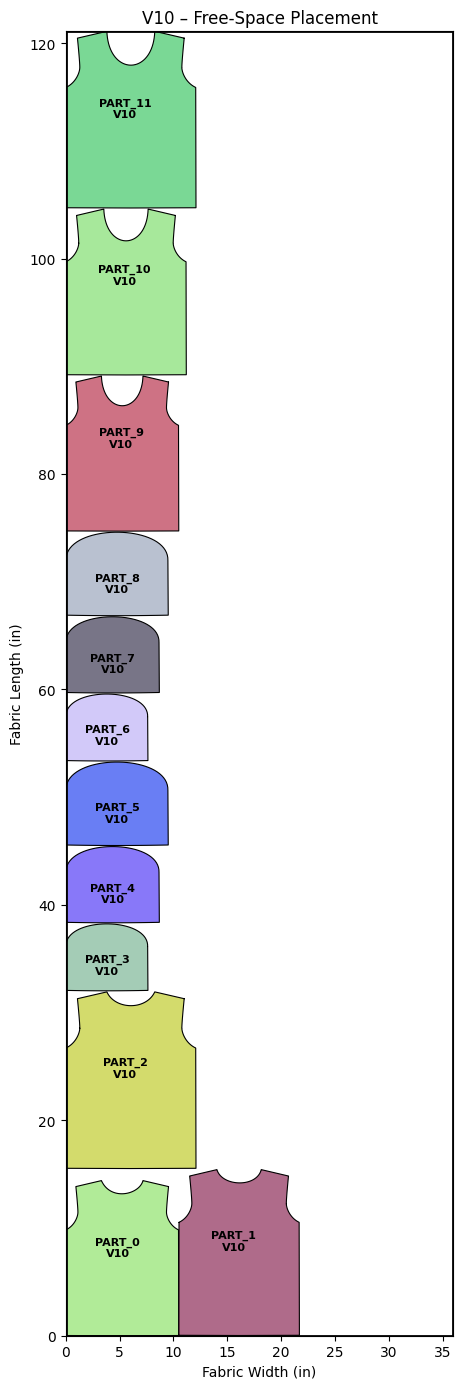

In [105]:
render_marker(
    placed_v10_items,
    strip_width=STRIP_WIDTH,
    title="V10 – Free-Space Placement",
    save_path="JK-123/v10_free_space.png"
)